<h1>IMPORTAÇÃO DE BIBLIOTECAS</h1>

In [65]:
import pandas as pd
import numpy as np

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

from imblearn.over_sampling import SMOTE

<h1>Criação de Pipelines </h1>

In [66]:
preprocessing_path = "./preprocessing/"

preprocessing_dataset_fileName = "05-preprocessing_dataset.csv"
ml_classification_dataset_filename = "06-ml_models_dataset.csv"
dense_classification_dataset_filename = "06-dense_modles_dataset.csv"

df_dataset = pd.read_csv(preprocessing_path+preprocessing_dataset_fileName)
df_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 13830 entries, 0 to 13829
Data columns (total 31 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   dataName              13830 non-null  str    
 1   motorSpeed            13830 non-null  float64
 2   load                  13830 non-null  float64
 3   class                 13830 non-null  str    
 4   rawData               13830 non-null  str    
 5   I_kurtosis            13830 non-null  float64
 6   I_max                 13830 non-null  float64
 7   I_median              13830 non-null  float64
 8   I_mode                13830 non-null  float64
 9   I_skewness            13830 non-null  float64
 10  Q_kurtosis            13830 non-null  float64
 11  Q_max                 13830 non-null  float64
 12  Q_min                 13830 non-null  float64
 13  Q_mode                13830 non-null  float64
 14  Q_skewness            13830 non-null  float64
 15  Q_std                 13830 no

In [67]:
data_numeric = df_dataset.select_dtypes(include="number")

pipeline_preprocessamento_class = LabelEncoder()
data_class = pipeline_preprocessamento_class.fit_transform(df_dataset['class'])

pipeline_preprocessamento_features = ColumnTransformer([
    ("scaler", MinMaxScaler(), data_numeric.columns)
], remainder="drop")

pipeline_machineLearning = Pipeline([
    ("preprocessamento", pipeline_preprocessamento_features),
    ("modelo", GaussianNB())
])

param_grid = [
    {
        "modelo": [GaussianNB()]
    },
    {
        "modelo":[DecisionTreeClassifier(random_state=0)],
        "modelo__criterion": ['gini', 'entropy'],
        "modelo__max_depth": [3,6,9]
    },
    {
        "modelo":[RandomForestClassifier(random_state=0)],
        "modelo__n_estimators": [10, 20, 30],
        "modelo__max_depth": [3,6,9],
        "modelo__min_samples_split": [2, 5, 10],
        "modelo__min_samples_leaf": [1, 2, 4]
    },
    {
        "modelo":[KNeighborsClassifier()],
        "modelo__n_neighbors":[3,5,7,10]
    }
]

grid_search = GridSearchCV(
    pipeline_machineLearning,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)


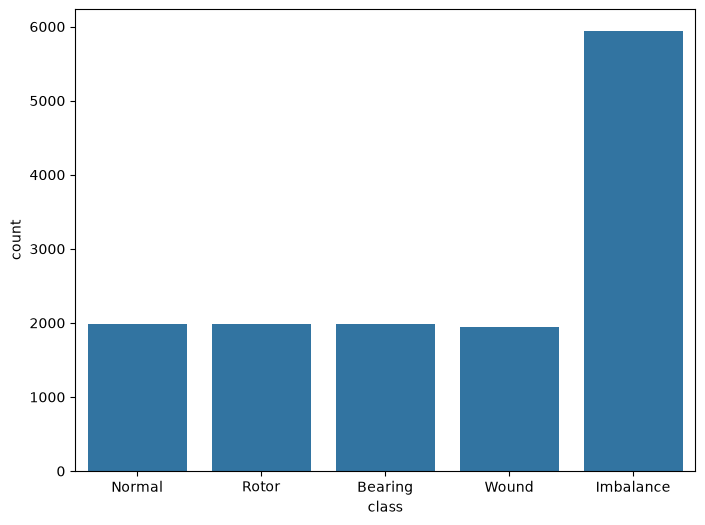

In [52]:
%matplotlib inline
plt.rcParams['figure.figsize'] = [8, 6]
sns.countplot(data=df_dataset, x="class")
plt.show()

In [53]:
X_train, X_test, y_train, y_test = train_test_split(data_numeric, data_class, test_size=0.7, random_state=0, stratify=data_class)

# criando uma instância do SMOTE
smote = SMOTE(random_state=42) 

# balanceando os dados
X_resampled, y_resampled = smote.fit_resample(X_train,y_train)

grid_search.fit(X_resampled, y_resampled)
print(f'Melhor pontuação: {grid_search.best_score_*100}%')
print(f'Melhor modelo: {grid_search.best_params_}')
print(f'Melhores parâmetros: {grid_search.best_params_}')
ml_results = pd.DataFrame(grid_search.cv_results_)

ml_results.to_csv(preprocessing_path+ml_classification_dataset_filename, index=False)
ml_results.head()

Melhor pontuação: 99.64085297418632%
Melhor modelo: {'modelo': RandomForestClassifier(random_state=0), 'modelo__max_depth': 9, 'modelo__min_samples_leaf': 1, 'modelo__min_samples_split': 2, 'modelo__n_estimators': 30}
Melhores parâmetros: {'modelo': RandomForestClassifier(random_state=0), 'modelo__max_depth': 9, 'modelo__min_samples_leaf': 1, 'modelo__min_samples_split': 2, 'modelo__n_estimators': 30}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_modelo,param_modelo__criterion,param_modelo__max_depth,param_modelo__min_samples_leaf,param_modelo__min_samples_split,param_modelo__n_estimators,param_modelo__n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.104638,0.005264,0.014284,0.002702,GaussianNB(),NaN,NaN,NaN,NaN,NaN,NaN,{'modelo': GaussianNB()},0.901235,0.916947,0.934905,0.927609,0.919753,0.920090,0.011327,90
1,0.236730,0.028788,0.011540,0.001922,DecisionTreeClassifier(random_state=0),gini,3.0,NaN,NaN,NaN,NaN,{'modelo': DecisionTreeClassifier(random_state...,0.764310,0.765993,0.775533,0.771605,0.771044,0.769697,0.004056,92
2,0.256939,0.050719,0.009513,0.001941,DecisionTreeClassifier(random_state=0),gini,6.0,NaN,NaN,NaN,NaN,{'modelo': DecisionTreeClassifier(random_state...,0.946128,0.942761,0.957351,0.954545,0.948934,0.949944,0.005352,89
3,0.288015,0.007248,0.012193,0.002619,DecisionTreeClassifier(random_state=0),gini,9.0,NaN,NaN,NaN,NaN,{'modelo': DecisionTreeClassifier(random_state...,0.974186,0.979237,0.987654,0.988777,0.984287,0.982828,0.005448,60
4,0.281237,0.028486,0.009089,0.002117,DecisionTreeClassifier(random_state=0),entropy,3.0,NaN,NaN,NaN,NaN,{'modelo': DecisionTreeClassifier(random_state...,0.886083,0.904040,0.907407,0.885522,0.909091,0.898429,0.010438,91


In [56]:
y_pred = grid_search.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99      1386
           1       0.99      1.00      0.99      4158
           2       1.00      1.00      1.00      1386
           3       1.00      0.98      0.99      1386
           4       1.00      1.00      1.00      1365

    accuracy                           0.99      9681
   macro avg       1.00      0.99      0.99      9681
weighted avg       0.99      0.99      0.99      9681



In [57]:
model = grid_search.best_estimator_
x = df_dataset.drop(columns=['class'])
y = pipeline_preprocessamento_class.transform(df_dataset['class'])

y_pred = model.predict(x)
results = pd.DataFrame({"y Real": pipeline_preprocessamento_class.inverse_transform(y), "y Predi": pipeline_preprocessamento_class.inverse_transform(y_pred)})
results[results["y Real"] != results["y Predi"]]

,y Real,y Predi
652,Normal,Imbalance
1340,Normal,Imbalance
2405,Rotor,Imbalance
2455,Rotor,Imbalance
2633,Rotor,Imbalance
...,...,...
12489,Imbalance,Normal
13148,Imbalance,Bearing
13155,Imbalance,Bearing
13158,Imbalance,Bearing


<h2>Rede Neural</h2>

In [58]:
import tensorflow as tf
from tensorflow import keras

In [59]:
dense_preprocessor_x= MinMaxScaler()
dense_encoder_y = OneHotEncoder(sparse_output=False)

#X_train, X_test, y_train, y_test = train_test_split(data_numeric, data_class, test_size=0.7, random_state=0, stratify=data_class)
X_train = dense_preprocessor_x.fit_transform(X_resampled)
X_test = dense_preprocessor_x.transform(X_test)

y_dense_train = dense_encoder_y.fit_transform(y_resampled.reshape(-1, 1))
y_dense_test = dense_encoder_y.transform(y_test.reshape(-1, 1))

num_class = len(dense_encoder_y.categories_[0])
num_features = data_numeric.shape[1]

print(f'Classes: {num_class}; Features: {num_features}')
data_numeric.describe()



Classes: 5; Features: 28


,motorSpeed,load,I_kurtosis,I_max,I_median,I_mode,I_skewness,Q_kurtosis,Q_max,Q_min,...,module_std,fase_amplitude,fase_energy,fase_kurtosis,fase_max,fase_mean,fase_mode,fft_bandwidth,fft_frequency_mean,fft_frequency_median
count,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,...,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000,13830.000000
mean,1000.650759,1.247289,2.756399,4.856370,2.562837,2.568327,0.059032,2.981233,4.625819,0.508221,...,0.753392,1.926893,6754.872133,7.226846,1.481098,0.788819,0.476168,818.294275,464.191280,163.530098
std,316.272827,0.852880,0.362579,0.383192,0.122037,1.178642,0.284410,0.472979,0.453228,0.365542,...,0.135335,0.927365,201.944570,8.548997,0.100995,0.011282,0.623110,66.281220,71.820979,48.155937
min,500.000000,0.000000,1.773020,0.488293,0.483187,-0.001887,-1.346414,1.083367,0.479195,-0.011126,...,0.002370,0.010669,4539.865816,1.466984,0.786562,0.510536,-1.570407,606.211482,247.490687,0.000000
25%,700.000000,0.500000,2.484575,4.613975,2.510286,2.188605,-0.108502,2.611241,4.253640,0.193175,...,0.684844,1.172084,6587.667416,2.756498,1.428544,0.780097,0.474945,774.562968,416.536086,127.987201
50%,1000.000000,1.000000,2.625663,4.935655,2.561346,2.525604,0.091734,2.830103,4.646917,0.504732,...,0.733848,1.361286,6780.592664,3.111874,1.512025,0.789922,0.621315,816.254213,465.968256,164.983502
75%,1300.000000,2.000000,2.956872,5.185851,2.637937,2.842178,0.300306,3.360099,5.019765,0.785645,...,0.821165,3.139180,6895.381279,6.645692,1.569336,0.795910,0.725403,859.034426,511.812958,199.980002
max,1500.000000,2.500000,3.842892,5.196064,2.862602,5.185851,0.665892,5.390342,5.193420,1.613060,...,1.676074,3.140608,9088.277637,48.265194,1.570175,0.846178,1.569502,1203.729567,738.272902,346.000000


In [60]:
model = keras.Sequential([
    keras.layers.Dense(num_features, activation="relu", input_shape=(num_features,)), #INPUT
    
    #keras.layers.Dense(2*num_features, activation="relu"),
    #keras.layers.Dense(int((num_features+num_class)/2), activation="relu"),
    #keras.layers.Dense(2*num_class, activation="relu"),
    
    keras.layers.Dense(num_class, activation="softmax") #OUTPUT
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

d:\MBA_IA_BIG_DATA\TCC\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 28)             │           812 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │           145 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 957 (3.74 KB)

 Trainable params: 957 (3.74 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
279/279 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6400 - loss: 1.3048
Epoch 2/10
279/279 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8816 - loss: 0.7287
Epoch 3/10
279/279 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9053 - loss: 0.4337
Epoch 4/10
279/279 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9172 - loss: 0.3144
Epoch 5/10
279/279 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9264 - loss: 0.2541
Epoch 6/10
279/279 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9377 - loss: 0.2141
Epoch 7/10
279/279 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9440 - loss: 0.1874
Epoch 8/10
279/279 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9505 - loss: 0.1657
Epoch 9/10
279/279 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9571 - loss: 0.1496
Epoch 10/10
279/279 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9594 - loss: 0.1367
279/279 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9625 - loss: 0.1309
Acurácia: 96.25%


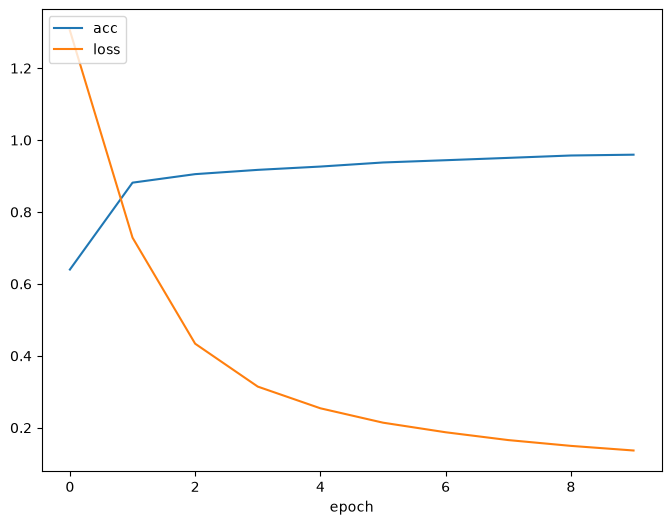

In [ ]:
%matplotlib inline
history = model.fit(X_train, y_dense_train, epochs=10)

test_loss, test_acc = model.evaluate(X_train, y_dense_train)
print(f'Acurácia: {test_acc*100:.02f}%')

# Mostrar graficamente
plt.plot(history.history['accuracy'])
plt.plot(history.history['loss'])
plt.xlabel('epoch')
plt.legend(['acc', 'loss'], loc='upper left')
plt.show()

In [62]:
y_pred_prob = model.predict(X_test)

y_pred_index = np.argmax(y_pred_prob, axis=1)

y_pred = dense_encoder_y.categories_[0][y_pred_index]

results = {
    "y_pred": y_pred,
    "y": y_test
}


df_result = pd.DataFrame(results)
df_result['test'] = df_result['y_pred'] == df_result['y']

print(df_result[df_result['test'] == False])


303/303 ━━━━━━━━━━━━━━━━━━━━ 0s 898us/step
      y_pred  y   test
76         4  1  False
79         0  1  False
81         0  1  False
99         3  1  False
116        1  3  False
...      ... ..    ...
9591       0  1  False
9609       1  0  False
9614       3  1  False
9617       0  1  False
9625       3  1  False

[561 rows x 3 columns]


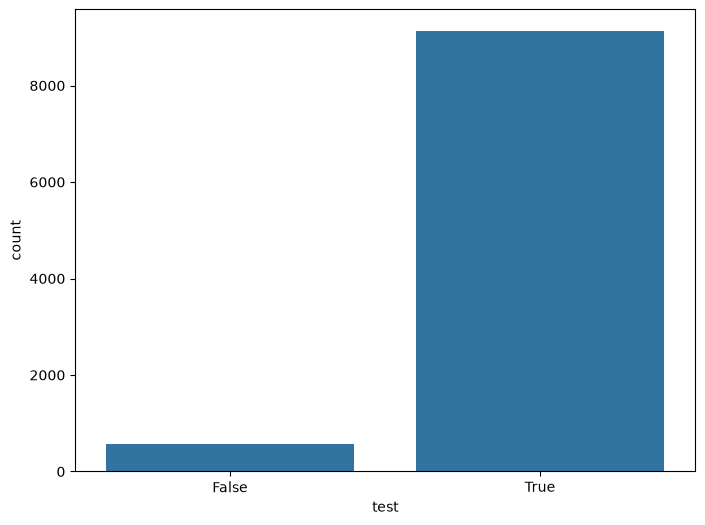

In [63]:
%matplotlib inline

plt.rcParams['figure.figsize'] = [8, 6]
sns.countplot(data=df_result, x="test")
plt.show()

In [64]:
df_erros = df_result[df_result['test'] == False]
df_erros.value_counts()

y_pred  y  test 
0       1  False    190
3       1  False    163
1       0  False    114
        3  False     65
2       1  False     12
4       1  False      6
3       0  False      3
4       0  False      3
1       4  False      2
        2  False      2
0       4  False      1
Name: count, dtype: int64